# FNEWS EDA — Label Semantics and Class Balance

Source taxonomy labels are not fact-checked factuality verdicts. NewsCLIPpings mismatch labels are excluded because there are zero validated local paired mismatch images.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
while not (ROOT / 'reports' / 'EDA').exists(): ROOT = ROOT.parent
EDA = ROOT / 'reports' / 'EDA'
FIG = EDA / 'figures'
summary = json.loads((EDA / 'eda_summary.json').read_text())
summary

{'verified_pairs': 4233,
 'splits': [{'dataset': 'Fakeddit research-v1',
   'split': 'train',
   'manifest_rows': 1185253,
   'verified_pairs': 2353,
   'text_available': 2353,
   'image_available': 2353,
   'raw_label_1_source_true': 1199,
   'raw_label_0_source_non_true': 1154},
  {'dataset': 'Fakeddit research-v1',
   'split': 'validate',
   'manifest_rows': 124425,
   'verified_pairs': 933,
   'text_available': 933,
   'image_available': 933,
   'raw_label_1_source_true': 377,
   'raw_label_0_source_non_true': 556},
  {'dataset': 'Fakeddit research-v1',
   'split': 'test',
   'manifest_rows': 125115,
   'verified_pairs': 947,
   'text_available': 947,
   'image_available': 947,
   'raw_label_1_source_true': 382,
   'raw_label_0_source_non_true': 565}],
 'readable_images': 4233,
 'corrupt_images': 0,
 'exact_text_cross_split_groups': 19,
 'exact_image_cross_split_groups': 0}

source_label,SOURCE_NON_TRUE,SOURCE_TRUE
split,,
test,565,382
train,1154,1199
validate,556,377


,records
6_way_label,
4,1126
2,703
1,216
5,155
3,75


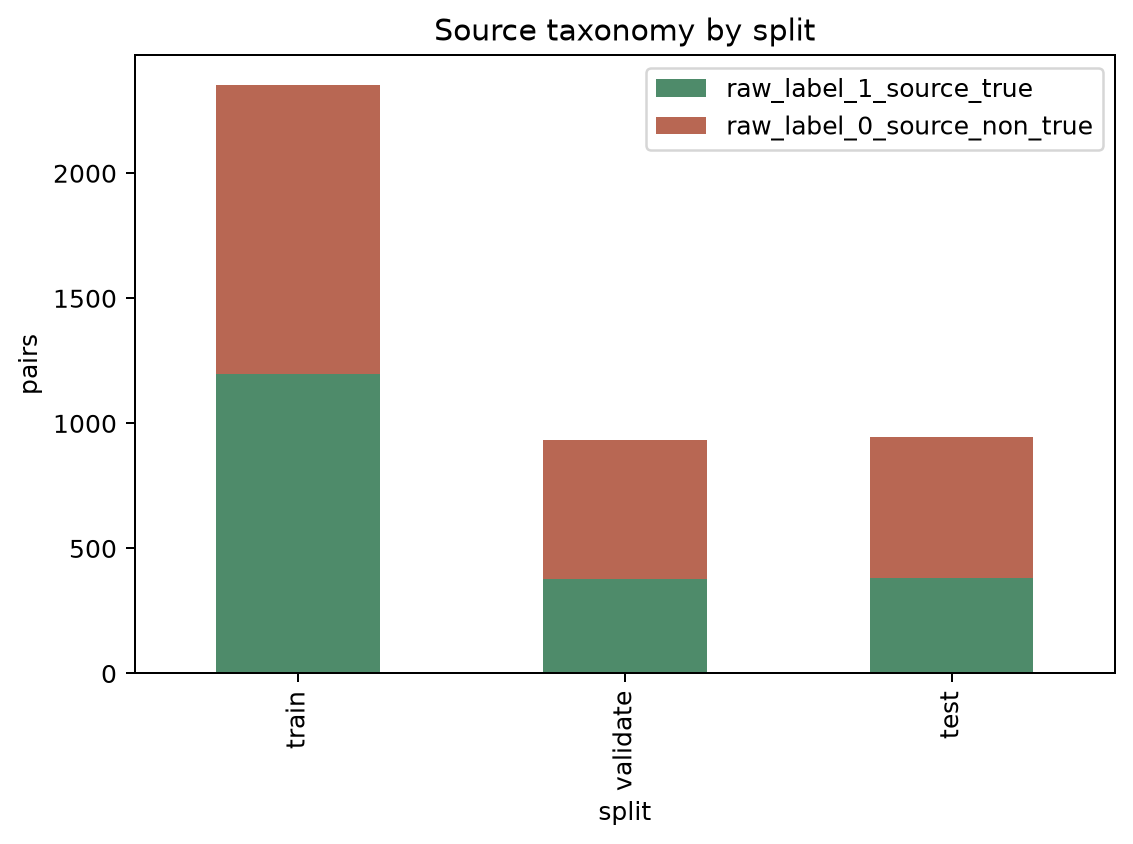

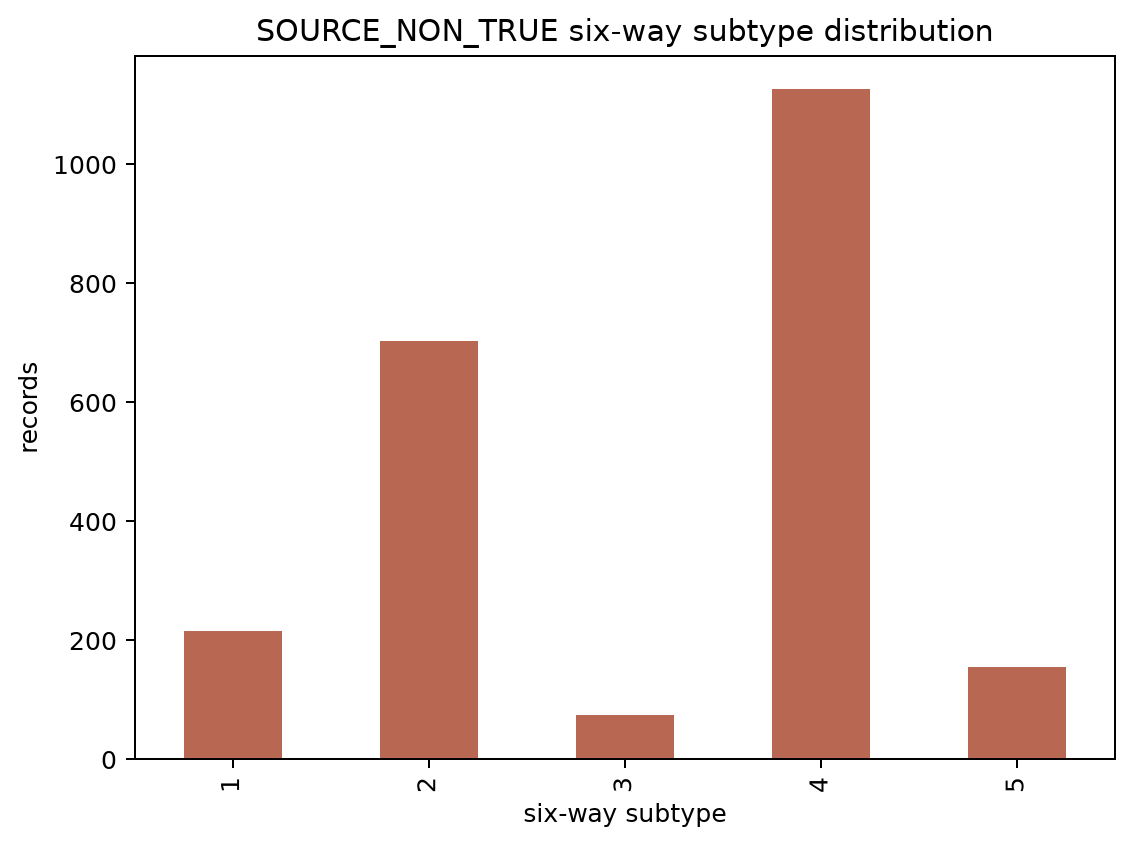

In [2]:
records=pd.read_parquet(EDA/'tables'/'paired_records_with_metadata.parquet')
display(records.groupby(['split','source_label']).size().unstack(fill_value=0))
display(records.loc[records.source_label.eq('SOURCE_NON_TRUE'),'6_way_label'].value_counts(dropna=False).rename('records').to_frame())
for n in ['02_class_by_split.png','19_non_true_subtypes.png']: display(Image(filename=str(FIG/n)))

### Reproducibility note

Generated from local manifests and processed images by `scripts/run_comprehensive_eda.py`. No external content was fetched and no model training occurred.